In [3]:
# # Session 10.11 — Exporting High-Quality Seaborn Charts
# # આજે આપણે શીખીશું કે Seaborn માં બનાવેલા charts ને high-quality PNG, SVG અને PDF ફાઇલ તરીકે કેવી રીતે save કરવા, presentation અથવા report માટે યોગ્ય quality કેવી રીતે રાખવી અને reusable chart template કેવી રીતે બનાવવી.

# # આ session Data Science માં ખૂબ ઉપયોગી છે, કારણ કે real-world projects માં visualization બનાવવું જ પૂરતું નથી — તેને report, presentation અને client સુધી યોગ્ય quality માં પહોંચાડવું પણ જરૂરી છે.

# 1. savefig() શું છે?
# Matplotlib નું savefig() function chart ને ફાઇલ તરીકે save કરે છે.

# plt.savefig("my_chart.png", dpi=300, bbox_inches="tight")

# Parameter	ઉપયોગ
# "my_chart.png"	ફાઇલનું નામ અને format
# dpi=300	image ની resolution/print quality
# bbox_inches="tight"	chart ની આસપાસની વધારાની ખાલી જગ્યા ઘટાડે છે
# pad_inches=0.2	chart ની આસપાસ કેટલી જગ્યા રાખવી
# transparent=True	background પારદર્શક રાખે છે
# facecolor="white"	background નો રંગ નક્કી કરે છે

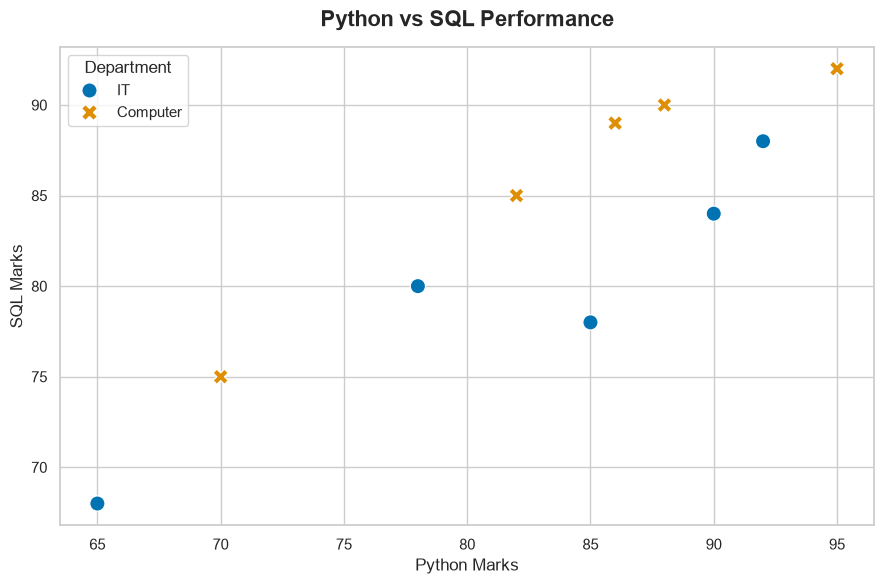

Chart successfully saved!


In [ ]:
# 3. Practical 1 — Seaborn chart ને PNG માં save કરો
# આ code ને VS Code ના Jupyter Notebook માં એક જ cell માં run કરો.
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Theme set કરવી
sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="colorblind"
)

# Dataset
data = {
    "Student": ["Amit", "Neha", "Ravi", "Pooja", "Karan",
                "Meera", "Jay", "Priya", "Rahul", "Nisha"],
    "Department": ["IT", "IT", "Computer", "Computer", "IT",
                   "Computer", "IT", "Computer", "IT", "Computer"],
    "Python": [85, 92, 70, 88, 65, 95, 78, 82, 90, 86],
    "SQL": [78, 88, 75, 90, 68, 92, 80, 85, 84, 89]
}

df = pd.DataFrame(data)

# Save કરવા માટે folder બનાવવો
os.makedirs("charts", exist_ok=True)

# Figure અને Axes બનાવવાં
fig, ax = plt.subplots(figsize=(9, 6))

# Seaborn chart
sns.scatterplot(
    data=df,
    x="Python",
    y="SQL",
    hue="Department",
    style="Department",
    s=120,
    ax=ax
)

# Chart ને professional બનાવવો
ax.set_title(
    "Python vs SQL Performance",
    fontsize=16,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Python Marks", fontsize=12)
ax.set_ylabel("SQL Marks", fontsize=12)
ax.legend(title="Department")

fig.tight_layout()

# પહેલાં save કરવો
fig.savefig(
    "charts/python_sql_chart.png",
    dpi=300, #chart ને 300 DPI ની PNG image તરીકે save કરે છે.
    bbox_inches="tight",
    facecolor="white"
)

# પછી display કરવો
plt.show()

print("Chart successfully saved!")


In [5]:
import os

print("Current directory:", os.getcwd())
print("Chart folder exists:", os.path.exists("charts"))
print("Chart saved:", os.path.exists("charts/python_sql_chart.png"))

Current directory: c:\Users\HP\OneDrive\Desktop\DA\Seaborn\12_session_11
Chart folder exists: True
Chart saved: True


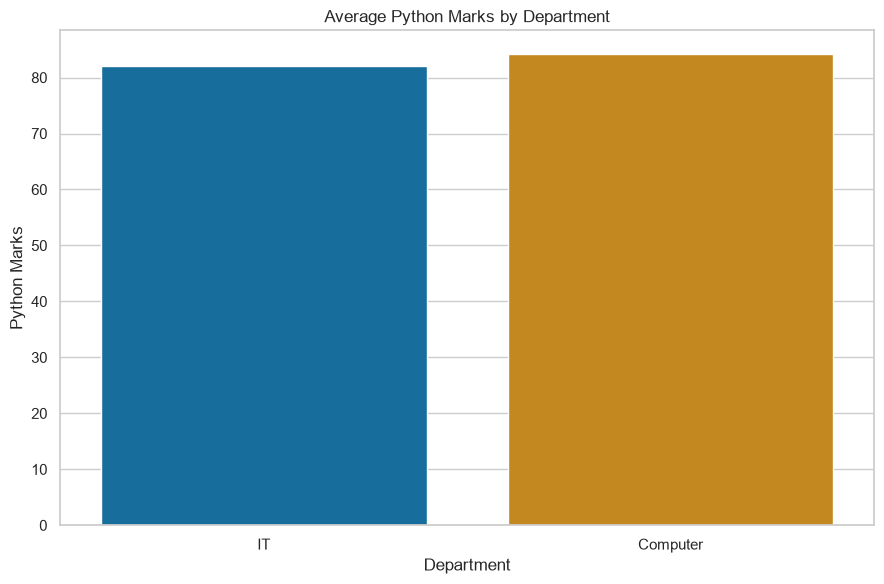

In [ ]:
# 5. Practical 2 — એક જ chart ને PNG, SVG અને PDF માં save કરો
# આ રીત professional projects માટે ઉપયોગી છે. એક વાર chart બનાવો અને જુદા formats માં export કરો.

fig, ax = plt.subplots(figsize=(9, 6))

sns.barplot(
    data=df,
    x="Department",
    y="Python",
    hue="Department",
    errorbar=None,
    ax=ax
)

ax.set_title("Average Python Marks by Department")
ax.set_xlabel("Department")
ax.set_ylabel("Python Marks")

fig.tight_layout()

# PNG: raster image
fig.savefig(
    "charts/python_marks.png",
    dpi=300,
    bbox_inches="tight"
)

# SVG: vector graphic
fig.savefig(
    "charts/python_marks.svg",
    bbox_inches="tight"
)

# PDF: report / print
fig.savefig(
    "charts/python_marks.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# અહીં errorbar=None confidence interval દૂર કરે છે. plt.close(fig) chart વાપરી લીધા પછી figure બંધ કરે છે, જે ઘણી figures બનાવતા હોય ત્યારે memory બચાવવામાં મદદ કરે છે.

# ધ્યાન આપો: જો તમારી Seaborn version જૂની હોય અને errorbar=None પર error આવે, તો તેને ci=None થી બદલી શકો છો

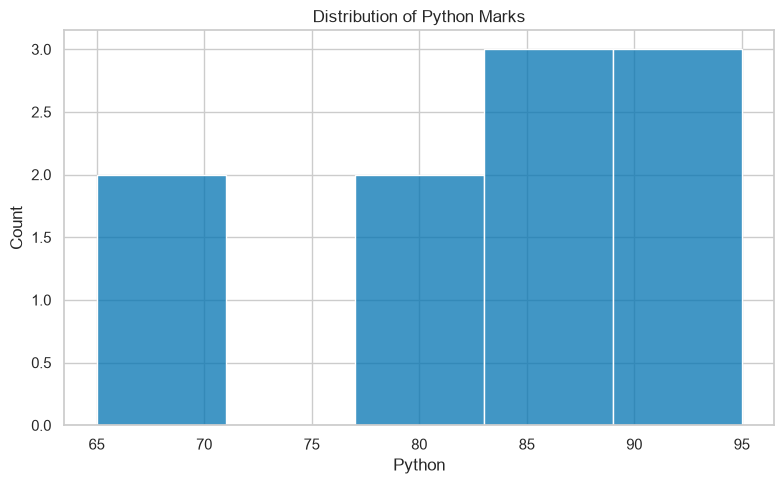

In [ ]:
# 6. Transparent background અને padding
# # ક્યારેક presentation માં chart નો background transparent જોઈએ, જેથી પાછળની slide નો રંગ દેખાય.

fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(data=df, x="Python", bins=5, ax=ax)

ax.set_title("Distribution of Python Marks")

fig.tight_layout()

fig.savefig(
    "charts/python_transparent.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.2, #chart ની આસપાસ થોડી જગ્યા રાખે છે.
    transparent=True #background transparent રાખે છે.
)

plt.show()

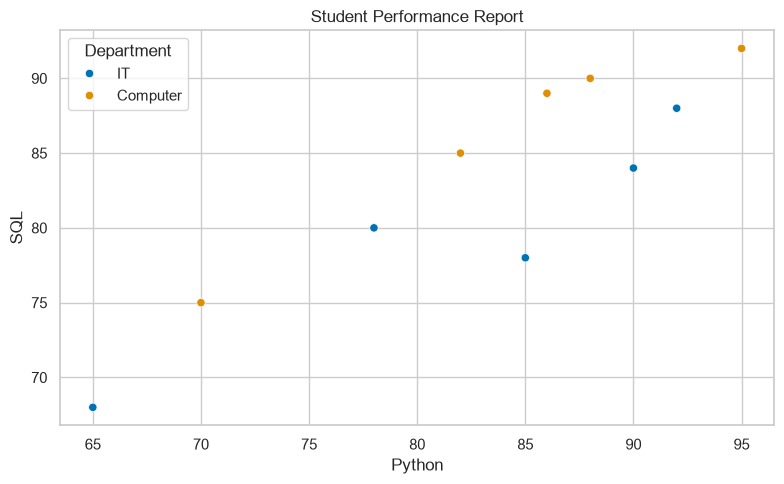

In [8]:
# 7. Reusable chart theme અને export functions
# દરેક chart માટે ફરીથી આખું styling અને saving code લખવાને બદલે functions બનાવી શકાય.

import os
import matplotlib.pyplot as plt
import seaborn as sns

def set_report_theme():
    sns.set_theme(
        style="whitegrid",
        context="notebook",
        palette="colorblind",
        font_scale=1.0
    )

def save_chart(fig, filename, dpi=300):
    os.makedirs("charts", exist_ok=True)

    fig.savefig(
        os.path.join("charts", filename),
        dpi=dpi,
        bbox_inches="tight",
        facecolor="white"
    )

# Theme લાગુ કરો
set_report_theme()

# Chart બનાવો
fig, ax = plt.subplots(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Python",
    y="SQL",
    hue="Department",
    ax=ax
)

ax.set_title("Student Performance Report")
fig.tight_layout()

# Export function વાપરો
save_chart(fig, "student_report.png")
plt.show()
plt.close(fig)

In [ ]:
# 10. Practical assignment
# આ checklist પૂરી કરીને તમારી પ્રેક્ટિસ તપાસો.
# Assignment progress
# 0/6



# [ ] Student dataset નો Seaborn chart બનાવ્યો.
# [ ] Chart ને 300 DPI સાથે PNG માં save કર્યો.
# [ ] એ જ chart ને SVG અને PDF માં export કર્યો.
# [ ] os.getcwd() વડે save location તપાસ્યું.
# [ ] Transparent background વાળો PNG બનાવ્યો.
# [ ] Reusable set_report_theme() અને save_chart() functions બનાવ્યાં.

